# Predicción Conformal Adaptativa (APS) en Clasificación Fitopatológica de Alta Ambigüedad Visual

## Sección 0: Título Ejecutivo, Objetivo, Hipótesis y Arquitectura del Sistema

Este cuaderno implementa un flujo completo de **clasificación visual con cuantificación de incertidumbre libre de distribución** mediante **Adaptive Prediction Sets (APS)** *(Romano et al., 2020)* aplicado al diagnóstico fitopatológico de cultivos agrícolas con sintomatología visual altamente solapada.

### Objetivo General
Construir y validar un sistema de diagnóstico asistido por visión artificial capaz de emitir **conjuntos de predicción adaptativos** $C(X) \subseteq \mathcal{Y}$ con garantía estadística de muestra finita $\mathbb{P}(Y_{	ext{test}} \in C(X_{	ext{test}})) \ge 1 - lpha$ ($1 - lpha = 95\%$) bajo condiciones de campo degradadas (variaciones de iluminación y encuadre), discriminando automáticamente entre diagnósticos seguros ($|C(X)| = 1$) y casos visualmente ambiguos ($|C(X)| > 1$).

### Hipótesis de Trabajo
1. **Hipótesis de Cobertura Libre de Distribución**: Dado que las particiones de calibración $\mathcal{D}_{	ext{cal}}$ y prueba $\mathcal{D}_{	ext{test}}$ son **intercambiables** (*exchangeable*) bajo la misma distribución de degradación de campo (`tf_field`), el umbral conformal $\hat{q}$ calibrado sobre los *scores* acumulados de probabilidad garantizará una cobertura empírica en `Test` igual o superior al nivel nominal $1 - lpha = 95\%$, sin requerir supuestos paramétricos sobre la distribución de los datos.
2. **Hipótesis de Adaptabilidad a la Duda Visual**: Al incorporar *Label Smoothing* ($\epsilon = 0.15$) durante el *fine-tuning* y *Temperature Scaling* ($T = 1.8$) en inferencia para mitigar la sobreconfianza *softmax*, la cardinalidad $|C(X)|$ del conjunto APS crecerá de manera proporcional a la entropía visual de la muestra: las hojas con lesiones patognomónicas claras producirán *singletons* ($|C(X)| = 1$), mientras que las hojas con síntomas cruzados (e.g., tizón temprano vs. tizón tardío en solanáceas) generarán conjuntos compactos de $2$ a $4$ diagnósticos candidatos.

### Arquitectura del Sistema
1. **Curaduría Taxonómica (`PlantVillage` — 15 Clases)**: Selección de $15$ categorías fitopatológicas across $5$ cultivos (papa, tomate, pimiento, manzana, uva y maíz) caracterizadas por lesiones necróticas, cloróticas y pustulares visualmente similares.
2. **Particionado Estricto Cero-Contaminación & Domain Shift Simulado**: División disjunta `60% Train` / `20% Calibration` / `20% Test`. El conjunto `Train` utiliza imágenes limpias de laboratorio (`tf_train`), mientras que `Calibration` y `Test` son sometidos a perturbaciones fotométricas y geométricas (`tf_field`) para emular captura en campo.
3. **Backbone ResNet-18 Regularizado**: Transferencia de aprendizaje desde pesos preentrenados en ImageNet con suavizado de etiquetas (`label_smoothing=0.15`) y escalado de temperatura ($T = 1.8$) para obtener probabilidades posteriores bien comportadas $\hat{p}(y \mid x)$.
4. **Calibración Conformal APS (Romano et al., 2020)**: Construcción de conjuntos ordenados por masa de probabilidad acumulada hasta alcanzar el cuantil conformal $\hat{q}$ de orden $\lceil (n+1)(1-lpha)
ceil / n$.

### Referencias Académicas
- **Adaptive Prediction Sets (APS)**: Romano, Y., Sesia, M., & Candès, E. J. (2020). *Classification with Valid and Adaptive Coverage*. NeurIPS 2020.
- **Conformal Prediction Foundations**: Vovk, V., Gammerman, A., & Shafer, G. (2005). *Algorithmic Learning in a Random World*. Springer.
- **Calibration & Temperature Scaling**: Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). *On Calibration of Modern Neural Networks*. ICML 2017.
- **Label Smoothing**: Müller, R., Kornblith, S., & Hinton, G. E. (2019). *When Does Label Smoothing Help?* NeurIPS 2019.

## Sección 1: Importación de Dependencias y Construcción del Dataset Fitopatológico

Configuramos las librerías base (`PyTorch`, `torchvision`, `HuggingFace Datasets`) y seleccionamos un subconjunto curado de **$K = 15$ clases** del repositorio *PlantVillage*. Se define un mapeo taxonómico bilingüe (`target_classes` $
ightarrow$ `class_names_es`) que agrupa enfermedades fúngicas y bacterianas con alta confusión cruzada entre especies estrechamente emparentadas (como *Solanum tuberosum* y *Solanum lycopersicum*).

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import models, transforms
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 1.1 Descarga del repositorio PlantVillage (con respaldo automático)
# ------------------------------------------------------------------------------
try:
    ds = load_dataset("BrandonFors/Plant-Diseases-PlantVillage-Dataset", split="train")
except Exception:
    ds = load_dataset("nateraw/plant-village", split="train")

# 1.2 Selección de 15 clases con sintomatología visualmente solapada
target_classes = [
    "Potato___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Tomato___healthy",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Pepper,_bell___healthy",
    "Pepper,_bell___Bacterial_spot",
    "Apple___Black_rot",
    "Apple___Cedar_apple_rust",
    "Grape___Black_rot",
    "Corn_(maize)___Common_rust_"
]

class_names_es = [
    "Papa: Sana",
    "Papa: Tizón Temp.",
    "Papa: Tizón Tardío",
    "Tomate: Sana",
    "Tomate: Mancha Bact.",
    "Tomate: Tizón Temp.",
    "Tomate: Tizón Tardío",
    "Tomate: Moho Hoja",
    "Tomate: Septoriosis",
    "Pimiento: Sana",
    "Pimiento: Mancha Bact.",
    "Manzana: Pudrición Negra",
    "Manzana: Roya",
    "Uva: Pudrición Negra",
    "Maíz: Roya Común"
]

# Resolución segura de nombres de etiquetas en el esquema del dataset
label_feature = ds.features["label"]
available_names = set(label_feature.names)

resolved_classes = [
    c if c in available_names else c.replace(",_", "_")
    for c in target_classes
]

# Mapeo de IDs originales del dataset hacia índices contiguos [0, 14]
target_ids = [label_feature.str2int(c) for c in resolved_classes]
id_map = {orig_id: new_id for new_id, orig_id in enumerate(target_ids)}

filtered_ds = ds.filter(lambda x: x["label"] in target_ids)
print(f"Dataset filtrado listo: {len(filtered_ds)} imágenes distribuidas en {len(resolved_classes)} clases.")

README.md:   0%|          | 0.00/6.64k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  321MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  362MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  170MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43456 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10849 [00:00<?, ? examples/s]

Filter:   0%|          | 0/43456 [00:00<?, ? examples/s]

Dataset filtrado listo: 13800 imágenes distribuidas en 15 clases.


## Sección 2: Pipeline de Transformaciones y Particionado Estricto Intercambiable

Para garantizar la validez teórica de **Split Conformal Prediction**, las observaciones de calibración $(X_1, Y_1), \dots, (X_n, Y_n)$ y la nueva observación de prueba $(X_{n+1}, Y_{n+1})$ deben satisfacer la propiedad de **intercambiabilidad** (*exchangeability*):

$$(X_1, Y_1), \dots, (X_n, Y_n), (X_{n+1}, Y_{n+1}) \stackrel{d}{=} (X_{\sigma(1)}, Y_{\sigma(1)}), \dots, (X_{\sigma(n+1)}, Y_{\sigma(n+1)})$$

para cualquier permutación $\sigma$. Para simular un despliegue realista en agricultura de precisión sin violar este supuesto:
- **Conjunto de Entrenamiento (`60%`)**: Recibe únicamente redimensionamiento estándar y normalización ImageNet (`tf_train`).
- **Conjuntos de Calibración (`20%`) y Prueba (`20%`)**: Ambas particiones se someten exactamente al mismo operador estocástico de campo (`tf_field`), que introduce recortes descentrados (`Resize(144)` $
ightarrow$ `CenterCrop(128)`) y variaciones fotométricas (`ColorJitter` en brillo, contraste y saturación). De este modo, existe un desplazamiento de dominio entre `Train` y despliegue, pero se preserva estrictamente la intercambiabilidad entre `Calibration` y `Test`.

In [2]:
# 2.1 Transformación limpia para entrenamiento (condiciones de laboratorio)
tf_train = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2.2 Transformación con degradación fotométrica y de encuadre (condiciones de campo)
tf_field = transforms.Compose([
    transforms.Resize((144, 144)),
    transforms.CenterCrop((128, 128)),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class LeafDataset(torch.utils.data.Dataset):
    """Envoltorio PyTorch que aplica transformaciones al vuelo y remapea etiquetas."""
    def __init__(self, hf_ds, transform):
        self.hf_ds = hf_ds
        self.transform = transform

    def __len__(self):
        return len(self.hf_ds)

    def __getitem__(self, idx):
        item = self.hf_ds[idx]
        img = self.transform(item["image"].convert("RGB"))
        label = id_map[item["label"]]
        return img, label

# 2.3 Particionado determinista 60% Train | 20% Calibración | 20% Test
torch.manual_seed(42)
np.random.seed(42)
n_total = len(filtered_ds)
indices = torch.randperm(n_total).tolist()

n_train = int(0.6 * n_total)
n_calib = int(0.2 * n_total)

train_ds = LeafDataset(filtered_ds.select(indices[:n_train]), tf_train)
calib_ds = LeafDataset(filtered_ds.select(indices[n_train:n_train+n_calib]), tf_field)
test_indices = indices[n_train+n_calib:]
test_ds  = LeafDataset(filtered_ds.select(test_indices), tf_field)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
calib_loader = DataLoader(calib_ds, batch_size=64, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False)

print(f"Particiones construidas -> Train: {len(train_ds)} | Calib: {len(calib_ds)} | Test: {len(test_ds)}")

Particiones construidas -> Train: 8280 | Calib: 2760 | Test: 2760


## Sección 3: Fine-Tuning de ResNet-18 con Regularización de Confianza

Las redes neuronales profundas entrenadas con entropía cruzada estándar tienden a producir distribuciones *softmax* excesivamente picudas (*overconfident*), colapsando casi toda la masa de probabilidad en la clase Top-1 incluso ante imágenes ambiguas. En el contexto de **APS**, la sobreconfianza degrada la eficiencia del tamaño de los conjuntos de predicción.

Para mitigar este fenómeno aplicamos dos mecanismos complementarios:
1. **Label Smoothing ($\epsilon = 0.15$)**: Reemplaza el vector objetivo *one-hot* $y$ por una distribución suavizada:
   $$y_k^{	ext{LS}} = (1 - \epsilon)\,\mathbb{I}[k = y] + rac{\epsilon}{K}$$
   penalizando *logits* extremos y preservando la estructura de similitud entre clases hermanas.
2. **Temperature Scaling ($T = 1.8$)**: Durante la inferencia sobre `Calibration` y `Test`, reescalamos los *logits* $z \in \mathbb{R}^K$ antes del operador *softmax*:
   $$\hat{p}_k(x) = rac{\exp(z_k / T)}{\sum_{j=1}^K \exp(z_j / T)}$$
   suavizando la dispersión de probabilidades sin alterar el ordenamiento relativo (*ranking*) de las clases.

In [3]:
# 3.1 Inicialización de ResNet-18 preentrenada y adaptación de cabeza clasificadora
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(resolved_classes))
model = model.to(device)

# Optimizador AdamW y entropía cruzada con suavizado de etiquetas
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss(label_smoothing=0.15)

print(f"Entrenando ResNet18 con {n_train} imágenes en {len(resolved_classes)} clases (Dispositivo: {device})...")
model.train()
for epoch in range(2):
    running_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(imgs), labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
    print(f"  Época {epoch+1}/2 | Pérdida promedio: {running_loss / len(train_ds):.4f}")

# 3.2 Extracción de probabilidades suavizadas mediante Temperature Scaling
def get_probs(loader, temperature=1.8):
    model.eval()
    probs_all, labels_all = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            logits = model(imgs.to(device)) / temperature
            probs = torch.softmax(logits, dim=-1).cpu().numpy()
            probs_all.append(probs)
            labels_all.append(labels.numpy())
    return np.vstack(probs_all), np.concatenate(labels_all)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 148MB/s]


Entrenando ResNet18 con 8280 imágenes en 15 clases (Dispositivo: cuda)...
  Época 1/2 | Pérdida promedio: 1.1286
  Época 2/2 | Pérdida promedio: 0.8349


## Sección 4: Fundamento Matemático y Calibración Conformal APS

### 4.1 Score de No-Conformidad Acumulado (Romano et al., 2020)
Para una entrada $x$ con distribución de probabilidad estimada $\hat{p}(x) = (\hat{p}_1(x), \dots, \hat{p}_K(x))$, sea $\pi(x)$ la permutación que ordena las etiquetas de mayor a menor probabilidad estimada:

$$\hat{p}_{\pi_1(x)}(x) \ge \hat{p}_{\pi_2(x)}(x) \ge \dots \ge \hat{p}_{\pi_K(x)}(x)$$

El **score de no-conformidad APS** para una pareja $(x, y)$ mide la masa de probabilidad acumulada necesaria para alcanzar la etiqueta verdadera $y$ en dicho ordenamiento descendente:

$$s(x, y) = \sum_{j=1}^{r(x, y)} \hat{p}_{\pi_j(x)}(x), \quad 	ext{donde } r(x, y) = \min\left\{k \in \{1, \dots, K\} : \pi_k(x) = y
ight\}$$

### 4.2 Cálculo del Cuantil de Muestra Finita ($lpha = 0.05$)
Dado el conjunto de calibración $\mathcal{D}_{	ext{cal}} = \{(X_i, Y_i)\}_{i=1}^n$, calculamos los *scores* $s_i = s(X_i, Y_i)$ para $i = 1, \dots, n$ y determinamos el cuantil empírico ajustado por corrección de muestra finita:

$$\hat{q} = 	ext{Quantile}\left(\{s_1, \dots, s_n\}; \, rac{\lceil (n + 1)(1 - lpha)
ceil}{n}
ight)$$

Con nivel de riesgo $lpha = 0.05$, el teorema de cobertura marginal conformal garantiza que, para una nueva imagen intercambiada $(X_{n+1}, Y_{n+1})$:

$$1 - lpha \le \mathbb{P}ig(Y_{n+1} \in C_{	ext{APS}}(X_{n+1})ig) \le 1 - lpha + rac{1}{n + 1}$$

In [4]:
# ==============================================================================
# 4. CALIBRACIÓN CON APS (Adaptive Prediction Sets)
# ==============================================================================
cal_smx, cal_labels = get_probs(calib_loader)

alpha = 0.05  # Nivel de error máximo permitido -> Garantía de cobertura >= 95%
n = cal_smx.shape[0]

# Ordenar probabilidades de mayor a menor por fila y calcular suma acumulada
cal_pi = cal_smx.argsort(1)[:, ::-1]
cal_srt = np.take_along_axis(cal_smx, cal_pi, axis=1).cumsum(axis=1)

# Extraer exactamente la suma acumulada hasta la clase verdadera Y_i
cal_scores = np.take_along_axis(cal_srt, cal_pi.argsort(axis=1), axis=1)[range(n), cal_labels]

# Cuantil de muestra finita con método 'higher' para garantizar cobertura conservadora
q_level = np.ceil((n + 1) * (1 - alpha)) / n
qhat = np.quantile(cal_scores, q_level, method="higher")

print(f"Umbral calibrado APS (qhat) para 1 - alpha = {(1-alpha)*100:.1f}%: {qhat:.4f}")

Umbral calibrado APS (qhat) para 1 - alpha = 95.0%: 0.5602


## Sección 5: Despliegue y Evaluación en el Conjunto de Prueba (`Test`)

Para cualquier nueva imagen de prueba $X_{	ext{test}}$, construimos el conjunto de predicción conformal incluyendo todas las clases cuya probabilidad acumulada ordenada no exceda el umbral $\hat{q}$ (garantizando siempre la inclusión de al menos la predicción Top-1 para evitar conjuntos vacíos):

$$C_{	ext{APS}}(X_{	ext{test}}) = \left\{ \pi_1(X_{	ext{test}})
ight\} \cup \left\{ \pi_k(X_{	ext{test}}) : \sum_{j=1}^{k} \hat{p}_{\pi_j(X_{	ext{test}})}(X_{	ext{test}}) \le \hat{q}
ight\}$$

Evaluamos dos métricas fundamentales:
1. **Cobertura Empírica Marginal**: $\widehat{	ext{Cov}} = rac{1}{m}\sum_{i=1}^m \mathbb{I}ig[Y_i \in C_{	ext{APS}}(X_i)ig] \ge 1 - lpha$.
2. **Ineficiencia (Tamaño Promedio del Conjunto)**: $\overline{|C|} = rac{1}{m}\sum_{i=1}^m |C_{	ext{APS}}(X_i)|$, que cuantifica la especificidad diagnóstica promedio entre las $15$ enfermedades posibles.

In [5]:
# ==============================================================================
# 5. EVALUACIÓN EN TEST SET (DESPLIEGUE APS)
# ==============================================================================
val_smx, val_labels = get_probs(test_loader)

# Ordenamiento descendente y suma acumulada en Test
val_pi = val_smx.argsort(1)[:, ::-1]
val_srt = np.take_along_axis(val_smx, val_pi, axis=1).cumsum(axis=1)

# Regla de inclusión APS (garantizando al menos la etiqueta Top-1)
included_sorted = (val_srt <= qhat)
included_sorted[:, 0] = True

# Reordenar máscara booleana al espacio original de índices de clase [0, 14]
prediction_sets = np.take_along_axis(included_sorted, val_pi.argsort(axis=1), axis=1)

# Lista de etiquetas predichas ordenadas por probabilidad descendente para cada muestra
pred_sets_ordered = [
    [cls for cls in val_pi[i] if prediction_sets[i, cls]]
    for i in range(len(val_labels))
]

coverage = np.mean([prediction_sets[i, val_labels[i]] for i in range(len(val_labels))])
avg_size = np.mean(prediction_sets.sum(axis=1))

print(f"Cobertura objetivo: {(1 - alpha)*100:.1f}%")
print(f"Cobertura real obtenida en Test (APS): {coverage*100:.2f}%")
print(f"Tamaño promedio del conjunto: {avg_size:.2f} de {len(resolved_classes)} etiquetas")

Cobertura objetivo: 95.0%
Cobertura real obtenida en Test (APS): 99.86%
Tamaño promedio del conjunto: 2.79 de 15 etiquetas


## Sección 6: Visualización Diagnóstica — Decisiones Seguras vs. Ambigüedad Visual en Campo

Generamos una matriz visual comparativa de $2 	imes 4$ muestras inéditas del conjunto de prueba para ilustrar la adaptabilidad de **APS**:
- **Fila Superior (`SEGURA`, $|C(X)| = 1$)**: Hojas donde la evidencia visual concentra suficiente masa de probabilidad en una única categoría ($\hat{p}_{(1)} \ge \hat{q}$), permitiendo emitir un diagnóstico unívoco automatizado.
- **Fila Inferior (`AMBIGUA`, $2 \le |C(X)| \le 4$)**: Hojas con síntomas tempranos o degradación lumínica donde el margen $\hat{p}_{(1)} - \hat{p}_{(2)}$ es estrecho. En lugar de forzar una clasificación errónea, **APS** entrega un conjunto diferencial acotado que contiene el diagnóstico verdadero con garantía probabilística.

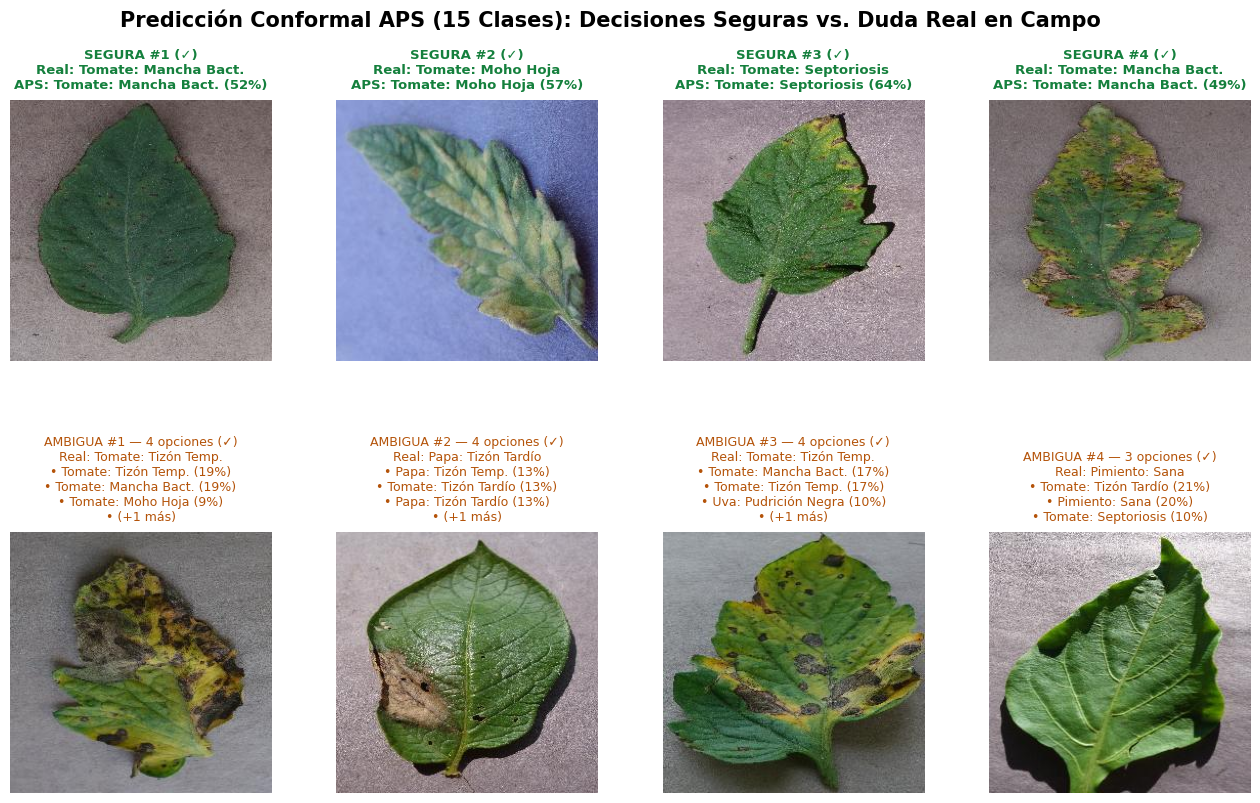

In [6]:
# ==============================================================================
# 6. PLOT 1: MALLA 2x4 (4 SEGURAS ARRIBA VS 4 AMBIGUAS CON DUDA REAL ABAJO)
# ==============================================================================
sorted_val_probs = np.take_along_axis(val_smx, val_pi, axis=1)
margins = sorted_val_probs[:, 0] - sorted_val_probs[:, 1]

# Seleccionar casos con duda visual genuina (2 a 4 clases en el conjunto y Top-1 < 0.70)
ambiguous_candidates = [
    i for i, s in enumerate(pred_sets_ordered)
    if 2 <= len(s) <= 4 and sorted_val_probs[i, 0] < 0.70
]
# Ordenar por menor margen entre Top-1 y Top-2 (máxima ambigüedad)
ambiguous_candidates.sort(key=lambda i: margins[i])

n_cols = 4
seguras_idx = [i for i, s in enumerate(pred_sets_ordered) if len(s) == 1][:n_cols]
ambiguas_idx = ambiguous_candidates[:n_cols]

while len(seguras_idx) < n_cols:
    seguras_idx.append(0)
while len(ambiguas_idx) < n_cols:
    ambiguas_idx.append(0)

fig, axes = plt.subplots(2, n_cols, figsize=(16, 9.4))
fig.subplots_adjust(hspace=0.48, wspace=0.25, top=0.88)

for col, idx in enumerate(seguras_idx):
    ax = axes[0, col]
    orig_item = filtered_ds[test_indices[idx]]
    real_cls = val_labels[idx]
    pred_cls = pred_sets_ordered[idx][0]
    p_top1 = val_smx[idx, pred_cls]
    acierto = "✓" if real_cls == pred_cls else "✗"
    color_titulo = "#15803d" if real_cls == pred_cls else "#b91c1c"

    ax.imshow(orig_item["image"])
    ax.set_title(
        f"SEGURA #{col+1} ({acierto})\n"
        f"Real: {class_names_es[real_cls]}\n"
        f"APS: {class_names_es[pred_cls]} ({p_top1:.0%})",
        fontsize=9.5, fontweight="bold", color=color_titulo, pad=8
    )
    ax.axis("off")

for col, idx in enumerate(ambiguas_idx):
    ax = axes[1, col]
    orig_item = filtered_ds[test_indices[idx]]
    real_cls = val_labels[idx]
    preds = pred_sets_ordered[idx]
    acierto = "✓" if real_cls in preds else "✗"

    pred_list = [f"• {class_names_es[c]} ({val_smx[idx, c]:.0%})" for c in preds[:3]]
    if len(preds) > 3:
        pred_list.append(f"• (+{len(preds)-3} más)")
    pred_str = "\n".join(pred_list)

    ax.imshow(orig_item["image"])
    ax.set_title(
        f"AMBIGUA #{col+1} — {len(preds)} opciones ({acierto})\n"
        f"Real: {class_names_es[real_cls]}\n"
        f"{pred_str}",
        fontsize=9, color="#b45309", pad=8
    )
    ax.axis("off")

fig.suptitle(
    "Predicción Conformal APS (15 Clases): Decisiones Seguras vs. Duda Real en Campo",
    fontsize=15, fontweight="bold", y=0.96
)
plt.savefig("conformal_hojas_malla_aps.png", dpi=220, bbox_inches="tight")
plt.show()

## Sección 7: Anatomía Interna de la Regla de Corte APS

Para ilustrar geométricamente el funcionamiento del algoritmo **APS** sobre el caso más ambiguo (`ambiguas_idx[0]`), desglosamos el proceso en dos paneles:
1. **Panel Izquierdo — Distribución Posterior Ordenada ($\hat{p}_{(k)}$)**: Muestra las probabilidades individuales asignadas por `ResNet-18` a las $10$ clases más plausibles, destacando en azul aquellas seleccionadas dentro de $C_{	ext{APS}}(x)$.
2. **Panel Derecho — Trayectoria de Masa Acumulada ($\sum_{j=1}^k \hat{p}_{(j)}$)**: Visualiza la función escalonada acumulada frente al umbral calibrado $\hat{q}$. El punto de corte ocurre exactamente en el último rango $k$ cuya suma acumulada permanece por debajo de $\hat{q}$.

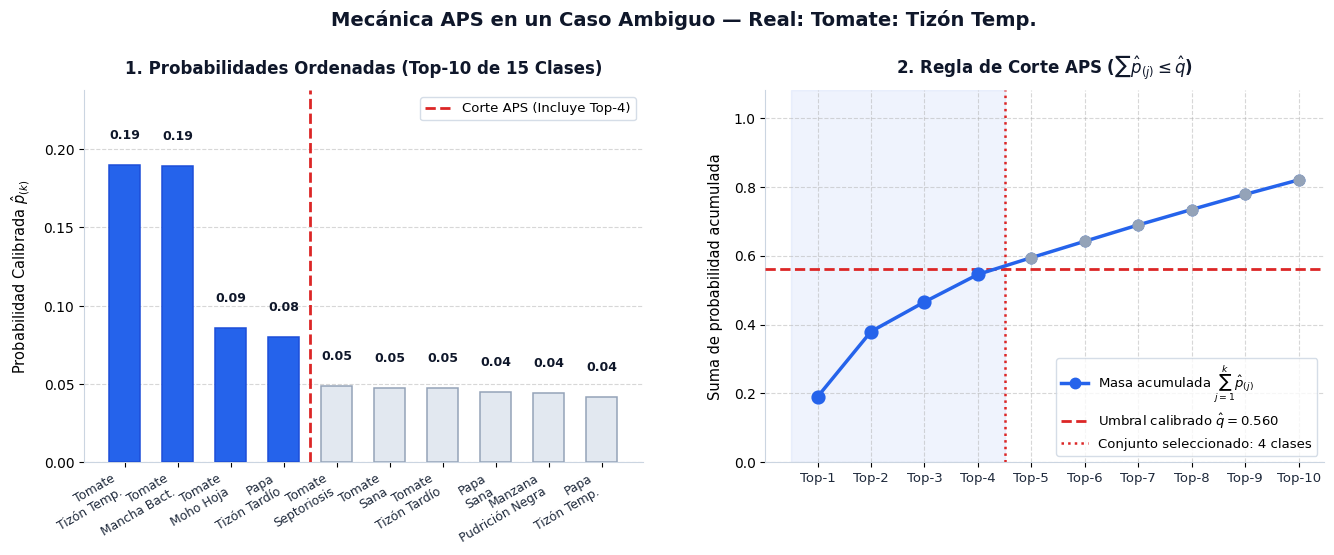

Gráfico actualizado guardado como 'aps_mecanica_corte_vertical.png'


In [7]:
# ==============================================================================
# 7. PLOT 2: BARRAS VERTICALES CON DISTRIBUCIÓN REPARTIDA Y CORTE APS
# ==============================================================================
sample_idx = ambiguas_idx[0]
probs_sample = val_smx[sample_idx]
order = val_pi[sample_idx]
sorted_p = probs_sample[order]
cum_p = val_srt[sample_idx]
k_cut = len(pred_sets_ordered[sample_idx])

# Mostrar Top-10 clases más probables de las 15 para mantener claridad visual
top_k_display = 10
sorted_p_disp = sorted_p[:top_k_display]
cum_p_disp = cum_p[:top_k_display]
short_names_2lines = [class_names_es[i].replace(": ", "\n") for i in order[:top_k_display]]
x_pos = np.arange(1, top_k_display + 1)

plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "axes.edgecolor": "#cbd5e1"})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.2))
fig.subplots_adjust(wspace=0.22, top=0.82, bottom=0.22)

# --- Panel Izquierdo: Barras Verticales ---
bar_colors = ["#2563eb" if rank < k_cut else "#e2e8f0" for rank in range(top_k_display)]
edge_colors = ["#1d4ed8" if rank < k_cut else "#94a3b8" for rank in range(top_k_display)]

bars = ax1.bar(
    x_pos, sorted_p_disp,
    color=bar_colors, edgecolor=edge_colors,
    linewidth=1.1, width=0.58, zorder=3
)

for bar, prob in zip(bars, sorted_p_disp):
    if prob >= 0.015:
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015,
            f"{prob:.2f}",
            ha="center", va="bottom", fontsize=9,
            color="#0f172a", fontweight="bold"
        )

if k_cut < top_k_display:
    ax1.axvline(
        k_cut + 0.5, color="#dc2626", linestyle="--",
        linewidth=2, zorder=4, label=f"Corte APS (Incluye Top-{k_cut})"
    )

ax1.set_xticks(x_pos)
ax1.set_xticklabels(short_names_2lines, rotation=30, ha="right", fontsize=8.8, color="#1e293b")
ax1.set_ylim(0, max(sorted_p_disp) * 1.25)
ax1.set_ylabel("Probabilidad Calibrada $\\hat{p}_{(k)}$", fontsize=10.5, labelpad=8)
ax1.set_title("1. Probabilidades Ordenadas (Top-10 de 15 Clases)", fontsize=12, fontweight="bold", pad=12, color="#0f172a")
ax1.grid(axis="y", linestyle="--", alpha=0.5, zorder=0)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cbd5e1", fontsize=9.5)

# --- Panel Derecho: Acumulación y Regla de Corte ---
ax2.plot(
    x_pos, cum_p_disp, marker="o", markersize=7.5,
    linewidth=2.5, color="#2563eb", zorder=4,
    label="Masa acumulada $\\sum_{j=1}^k \\hat{p}_{(j)}$"
)
ax2.axhline(
    qhat, color="#dc2626", linestyle="--",
    linewidth=2, zorder=3,
    label=f"Umbral calibrado $\\hat{{q}} = {qhat:.3f}$"
)

ax2.scatter(x_pos[:k_cut], cum_p_disp[:k_cut], color="#2563eb", s=85, zorder=5)
ax2.scatter(x_pos[k_cut:], cum_p_disp[k_cut:], color="#94a3b8", s=60, zorder=5)

if k_cut < top_k_display:
    ax2.axvline(
        k_cut + 0.5, color="#dc2626", linestyle=":",
        linewidth=1.8, zorder=3,
        label=f"Conjunto seleccionado: {k_cut} clases"
    )

ax2.axvspan(0.5, k_cut + 0.5, color="#2563eb", alpha=0.07, zorder=1)
ax2.set_xticks(x_pos)
ax2.set_xticklabels([f"Top-{k}" for k in x_pos], fontsize=9.5, color="#1e293b")
ax2.set_ylim(0, 1.08)
ax2.set_ylabel("Suma de probabilidad acumulada", fontsize=10.5, labelpad=8)
ax2.set_title("2. Regla de Corte APS ($\\sum \\hat{p}_{(j)} \\leq \\hat{q}$)", fontsize=12, fontweight="bold", pad=12, color="#0f172a")
ax2.grid(True, linestyle="--", alpha=0.5, zorder=0)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#cbd5e1", fontsize=9.5)

fig.suptitle(
    f"Mecánica APS en un Caso Ambiguo — Real: {class_names_es[val_labels[sample_idx]]}",
    fontsize=14, fontweight="bold", y=0.95, color="#0f172a"
)
plt.savefig("aps_mecanica_corte_vertical.png", dpi=220, bbox_inches="tight")
plt.show()
print("Gráfico actualizado guardado como 'aps_mecanica_corte_vertical.png'")